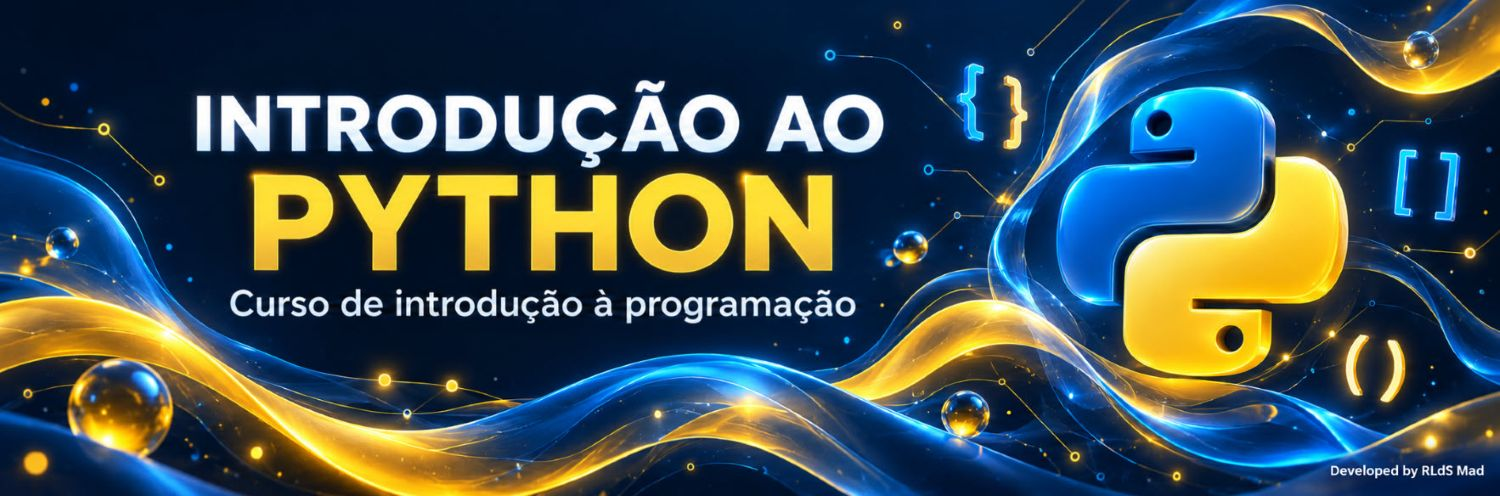

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_04_Redes_Neuronais_NumPy.ipynb)


# Nível IA · Módulo 4 – Redes neuronais de raiz, com NumPy
## Do neurónio à retropropagação

As redes neuronais estão por trás do reconhecimento de imagem, da tradução automática e dos modelos de linguagem. Bibliotecas como o PyTorch tornam-nas fáceis de usar, mas também escondem o que se passa lá dentro. Neste módulo constróis uma rede neuronal **de raiz**, só com NumPy: cada multiplicação, cada derivada e cada atualização dos pesos é código teu. No módulo seguinte vais ver o PyTorch fazer o mesmo em poucas linhas, e vais saber exatamente o que ele está a fazer por ti.

A matemática fica pelo essencial: somas ponderadas, derivadas simples e a regra da cadeia, sempre acompanhadas de código e de gráficos. Quando aparece uma fórmula, aparece logo a seguir a linha de NumPy que a calcula.

> **Objetivos:** perceber o neurónio como soma ponderada mais função de ativação, e a sua relação com a regressão logística; conhecer as funções de ativação e porque são necessárias; minimizar uma função de perda com descida do gradiente e escolher a taxa de aprendizagem; construir uma rede com uma camada escondida e controlar as dimensões das matrizes; implementar a retropropagação e verificá-la com diferenças finitas; treinar com mini-lotes, acompanhar as curvas de treino e validação e combater o sobreajuste; comparar com o scikit-learn e preparar a passagem para o PyTorch.

**Pré-requisitos:** NumPy (capítulo 22), visualização (capítulo 24), classes (capítulo 20), geradores e anotações de tipo (capítulo 25) e classificação com scikit-learn (módulo N2_04). Não é preciso saber cálculo: as derivadas usadas são explicadas quando aparecem.

| Secção | Tema |
| --- | --- |
| 0. Preparação | bibliotecas e notação |
| 1. Um neurónio | soma ponderada, regressão logística, E, OU e o problema do XOR |
| 2. Funções de ativação | sigmoide, tanh, ReLU e as suas derivadas |
| 3. Perda e descida do gradiente | como uma rede aprende; a taxa de aprendizagem |
| 4. Uma rede com uma camada escondida | dimensões, propagação para a frente, inicialização |
| 5. Retropropagação | a regra da cadeia e a verificação dos gradientes |
| 6. Treinar a rede | mini-lotes, curvas de aprendizagem, sobreajuste |
| 7. Comparar e ligar ao PyTorch | scikit-learn e o que o PyTorch automatiza |
| 8. Experimenta | três exercícios com solução |


## 0. Preparação

### 0.1 Bibliotecas

Só precisamos de NumPy e matplotlib. O scikit-learn serve apenas para gerar os dados e para a comparação final.


In [1]:
# Executar esta célula

import copy

import matplotlib.pyplot as plt
import numpy as np
import sklearn
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)
print(f"NumPy {np.__version__} | scikit-learn {sklearn.__version__}")

NumPy 2.5.4 | scikit-learn 1.9.1


### 0.2 Notação

| Símbolo | Significado | No código |
| --- | --- | --- |
| $x$ | entradas de um exemplo (os atributos) | `X` (uma linha por exemplo) |
| $w$, $b$ | pesos e viés (*bias*): os parâmetros que a rede aprende | `W1`, `b1`, `W2`, `b2` |
| $z = x \cdot w + b$ | soma ponderada | `Z1`, `Z2` |
| $a = g(z)$ | saída de um neurónio depois da função de ativação $g$ | `A1`, `A2` |
| $\hat{y}$ | previsão da rede (aqui, uma probabilidade) | `A2` |
| $L$ | perda: quanto a previsão está errada | `perda` |
| $\frac{\partial L}{\partial w}$ | gradiente: quanto a perda muda quando $w$ muda um pouco | `dW1`, `dW2` |
| $\eta$ | taxa de aprendizagem (*learning rate*) | `taxa` |


## 1. Um neurónio

Um neurónio artificial faz duas coisas:

1. calcula uma **soma ponderada** das entradas: $z = w_1 x_1 + w_2 x_2 + \dots + b$;
2. aplica uma **função de ativação** $g$ a essa soma: $a = g(z)$.

Os pesos $w$ dizem a importância de cada entrada; o viés $b$ desloca o resultado. Com a função **sigmoide**, $\sigma(z) = \frac{1}{1 + e^{-z}}$, a saída fica entre 0 e 1 e pode ler-se como uma probabilidade.

Com NumPy, a soma ponderada de **todos os exemplos de uma vez** é um produto de matrizes: `X @ w + b` (capítulo 22).


In [2]:
# Executar esta célula

def sigmoide(z: np.ndarray) -> np.ndarray:
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))      # clip evita avisos de overflow


def neuronio(X: np.ndarray, w: np.ndarray, b: float) -> np.ndarray:
    """Saída de um neurónio sigmoide para cada linha de X."""
    return sigmoide(X @ w + b)


X_logica = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
print("Entradas:\n", X_logica)
print("Neurónio com w = [1, 1] e b = 0:", neuronio(X_logica, np.array([1.0, 1.0]), 0.0))

Entradas:
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]
Neurónio com w = [1, 1] e b = 0: [0.5    0.7311 0.7311 0.8808]


### 1.1 O neurónio é uma regressão logística

Se isto te parece familiar, é porque é: **um neurónio sigmoide é exatamente uma regressão logística** (módulo N2_04). A regressão logística do scikit-learn aprende os pesos (`coef_`) e o viés (`intercept_`); usando-os no nosso neurónio, obtemos as mesmas probabilidades.


In [3]:
# Executar esta célula

X_luas, y_luas = make_moons(n_samples=200, noise=0.2, random_state=0)
logistica = LogisticRegression().fit(X_luas, y_luas)

p_sklearn = logistica.predict_proba(X_luas)[:, 1]
p_neuronio = neuronio(X_luas, logistica.coef_[0], logistica.intercept_[0])
print("Pesos:", logistica.coef_[0], "| viés:", logistica.intercept_[0].round(4))
print("Mesmas probabilidades?", np.allclose(p_sklearn, p_neuronio))

Pesos: [ 1.0886 -3.3506] | viés: 0.3511
Mesmas probabilidades? True


### 1.2 Um neurónio pode fazer de porta lógica…

Com os pesos certos, um neurónio reproduz as operações lógicas **E** (*AND*) e **OU** (*OR*). Por exemplo, com $w = (10, 10)$:
- com $b = -15$, a soma só é positiva quando as duas entradas são 1: é o **E**;
- com $b = -5$, basta uma entrada a 1: é o **OU**.


In [4]:
# Executar esta célula

w = np.array([10.0, 10.0])
for nome, b, esperado in [("E", -15, [0, 0, 0, 1]), ("OU", -5, [0, 1, 1, 1])]:
    saida = neuronio(X_logica, w, b)
    print(f"{nome:<3} saída: {saida.round(3)} → arredondada {saida.round().astype(int)} | esperado {esperado}")

E   saída: [0.    0.007 0.007 0.993] → arredondada [0 0 0 1] | esperado [0, 0, 0, 1]
OU  saída: [0.007 0.993 0.993 1.   ] → arredondada [0 1 1 1] | esperado [0, 1, 1, 1]


### 1.3 …mas não resolve o XOR

O **OU exclusivo** (XOR) dá 1 quando as entradas são **diferentes**. Nenhum conjunto de pesos o resolve com um só neurónio. A razão vê-se num gráfico: a fronteira de decisão de um neurónio é uma **reta** ($w_1 x_1 + w_2 x_2 + b = 0$), e nenhuma reta separa os pontos do XOR.


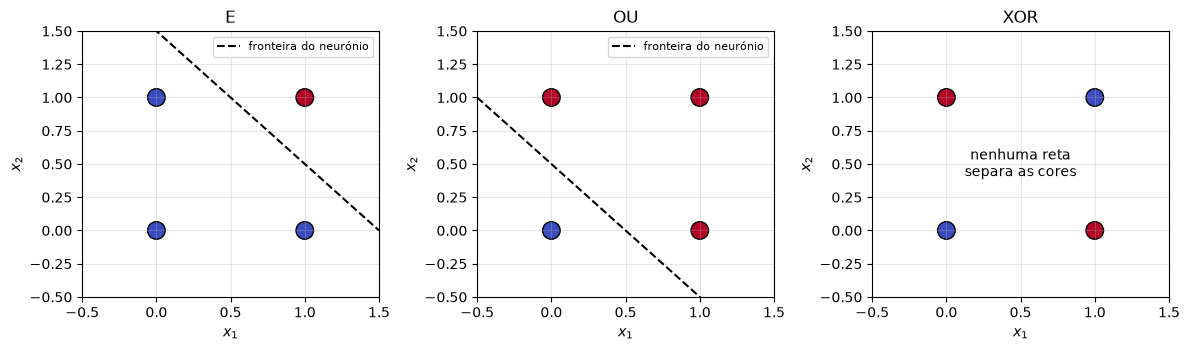

In [5]:
# Executar esta célula

fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
xs = np.linspace(-0.5, 1.5, 50)
for ax, (nome, y_porta, b) in zip(axs, [("E", [0, 0, 0, 1], -15), ("OU", [0, 1, 1, 1], -5), ("XOR", [0, 1, 1, 0], None)]):
    ax.scatter(X_logica[:, 0], X_logica[:, 1], c=y_porta, cmap="coolwarm", s=160, edgecolor="k", vmin=0, vmax=1)
    if b is not None:
        ax.plot(xs, (-b - 10 * xs) / 10, color="k", ls="--", label="fronteira do neurónio")
        ax.legend(loc="upper right", fontsize=8)
    else:
        ax.text(0.5, 0.5, "nenhuma reta\nsepara as cores", ha="center", va="center", fontsize=10)
    ax.set(title=nome, xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xlabel="$x_1$", ylabel="$x_2$")
plt.tight_layout()
plt.show()

A solução, descoberta nos anos 1980, é **juntar neurónios em camadas**: uma camada escondida transforma as entradas num novo espaço onde a separação já é possível. Mas, para que isso funcione, cada neurónio tem de ter uma função de ativação **não linear**. É o tema da secção seguinte.


## 2. Funções de ativação

### 2.1 Porque são necessárias

Sem função de ativação, uma camada é só uma multiplicação de matrizes. E duas multiplicações seguidas são… outra multiplicação: $(X W_1) W_2 = X (W_1 W_2)$. Empilhar camadas lineares não acrescenta nada: o resultado continua a ser uma única camada linear, com uma fronteira reta.


In [6]:
# Executar esta célula

rng = np.random.default_rng(0)
X_teste_lin = rng.normal(size=(5, 2))
W1_lin, W2_lin = rng.normal(size=(2, 4)), rng.normal(size=(4, 1))
duas_camadas = (X_teste_lin @ W1_lin) @ W2_lin
uma_camada = X_teste_lin @ (W1_lin @ W2_lin)
print("Duas camadas lineares = uma camada linear?", np.allclose(duas_camadas, uma_camada))

Duas camadas lineares = uma camada linear? True


### 2.2 As funções mais usadas

| Função | Fórmula | Saída | Derivada | Onde se usa |
| --- | --- | --- | --- | --- |
| **sigmoide** | $\sigma(z) = \frac{1}{1+e^{-z}}$ | 0 a 1 | $\sigma(z)\,(1-\sigma(z))$ | camada de saída em classificação binária |
| **tanh** | $\tanh(z)$ | −1 a 1 | $1 - \tanh^2(z)$ | camadas escondidas (mais antiga) |
| **ReLU** | $\max(0, z)$ | 0 a ∞ | 1 se $z > 0$, senão 0 | camadas escondidas (a mais usada hoje) |

A **derivada** diz quanto a saída muda quando $z$ muda um pouco. Vamos precisar dela na retropropagação (secção 5). Guardamos cada função com a sua derivada num dicionário, para as podermos trocar facilmente.


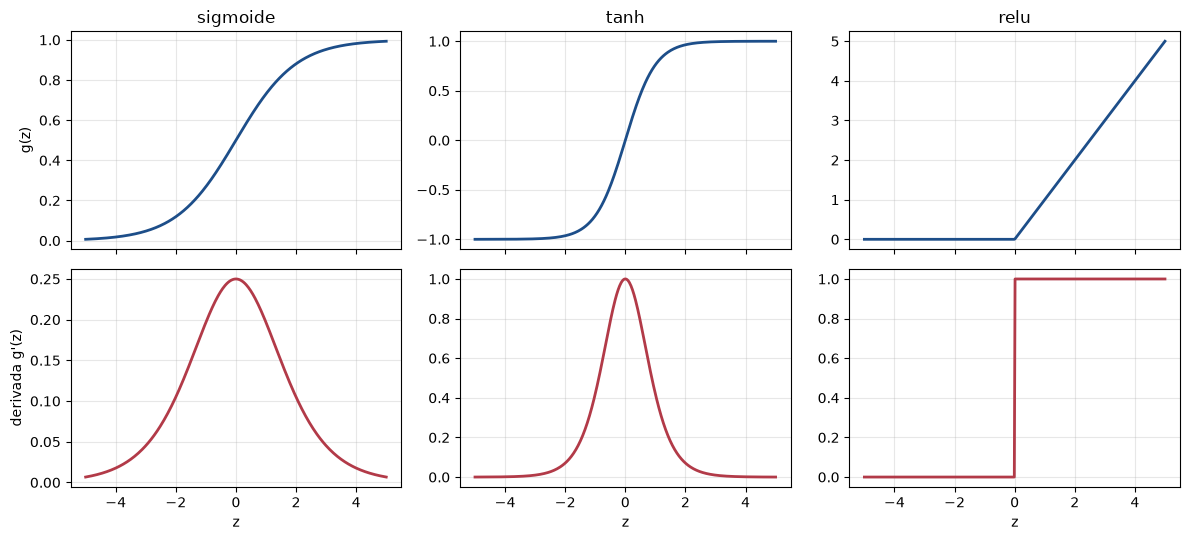

In [7]:
# Executar esta célula

def relu(z: np.ndarray) -> np.ndarray:
    return np.maximum(0, z)


ATIVACOES = {
    "sigmoide": (sigmoide, lambda z: sigmoide(z) * (1 - sigmoide(z))),
    "tanh": (np.tanh, lambda z: 1 - np.tanh(z) ** 2),
    "relu": (relu, lambda z: (z > 0).astype(float)),
}

z = np.linspace(-5, 5, 400)
fig, axs = plt.subplots(2, 3, figsize=(12, 5.5), sharex=True)
for j, (nome, (g, dg)) in enumerate(ATIVACOES.items()):
    axs[0, j].plot(z, g(z), color="#1D4E89", lw=2)
    axs[0, j].set_title(nome)
    axs[1, j].plot(z, dg(z), color="#B23A48", lw=2)
    axs[1, j].set_xlabel("z")
axs[0, 0].set_ylabel("g(z)")
axs[1, 0].set_ylabel("derivada g'(z)")
plt.tight_layout()
plt.show()

Repara nas derivadas (em baixo):

- a derivada da **sigmoide** nunca passa de 0,25, e fica quase **zero** para $|z|$ grande. Numa rede com muitas camadas, as derivadas multiplicam-se umas pelas outras (secção 5) e o sinal de aprendizagem vai encolhendo até quase desaparecer: é o **problema do gradiente que desaparece** (*vanishing gradient*);
- a **ReLU** tem derivada 1 para todo o $z$ positivo: o gradiente passa sem encolher. É uma das razões por que tornou possível treinar redes profundas. Em contrapartida, um neurónio com $z$ sempre negativo deixa de aprender (derivada 0).

Por isso, a combinação habitual é **ReLU nas camadas escondidas** e **sigmoide na saída** (para classificação binária). É a que vamos usar.


## 3. Perda e descida do gradiente: como uma rede aprende

### 3.1 A função de perda

Para aprender, a rede precisa de saber **quão errada** está. A **função de perda** transforma os erros num único número, que queremos tornar o mais pequeno possível.

| Perda | Fórmula (média em $n$ exemplos) | Para |
| --- | --- | --- |
| **erro quadrático médio** (EQM) | $\frac{1}{n}\sum (\hat{y} - y)^2$ | regressão (prever números) |
| **entropia cruzada binária** | $-\frac{1}{n}\sum \left[y \log \hat{y} + (1-y)\log(1-\hat{y})\right]$ | classificação binária (prever probabilidades) |

A entropia cruzada castiga muito as previsões **confiantes e erradas**: prever 0,01 quando a resposta é 1 custa muito mais do que prever 0,4.


In [8]:
# Executar esta célula

def entropia_cruzada(y: np.ndarray, p: np.ndarray) -> float:
    p = np.clip(p, 1e-12, 1 - 1e-12)                    # evita log(0)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


for p in [0.99, 0.6, 0.4, 0.01]:
    print(f"resposta certa = 1, previsão = {p:<4} → perda {entropia_cruzada(np.array([1]), np.array([p])):.3f}")

resposta certa = 1, previsão = 0.99 → perda 0.010
resposta certa = 1, previsão = 0.6  → perda 0.511
resposta certa = 1, previsão = 0.4  → perda 0.916
resposta certa = 1, previsão = 0.01 → perda 4.605


### 3.2 Descida do gradiente numa variável

Como encontrar os pesos que tornam a perda mínima? A ideia da **descida do gradiente** é a de quem desce uma montanha com nevoeiro: em cada passo, sente a inclinação do terreno e dá um passo no sentido da descida.

A inclinação é a **derivada** (o **gradiente**, quando há vários pesos). A regra de atualização é:

$$w \leftarrow w - \eta \, \frac{\partial L}{\partial w}$$

onde $\eta$ é a **taxa de aprendizagem**: o tamanho do passo. Vejamos com uma função simples, $L(w) = (w - 3)^2$, cujo mínimo está em $w = 3$ e cuja derivada é $2(w - 3)$.


η = 0.05  → w final = 1.971
η = 0.3   → w final = 3.000
η = 1.05  → w final = 23.886


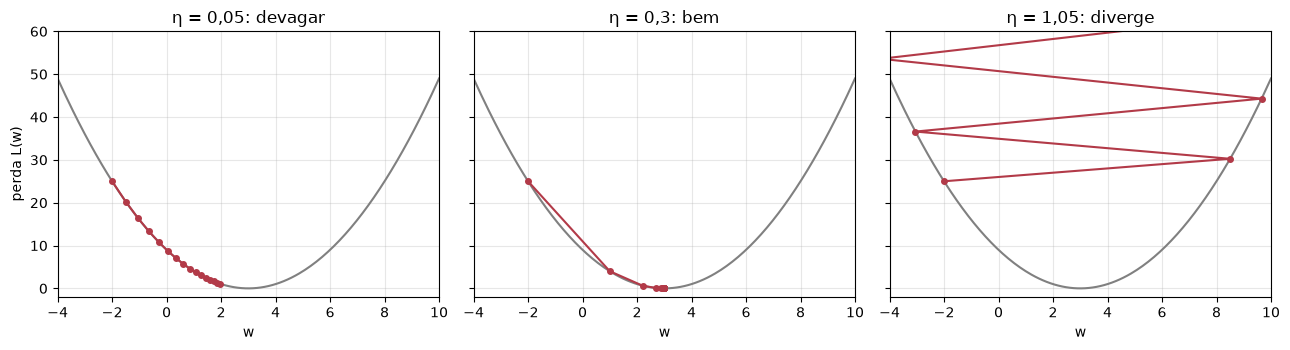

In [9]:
# Executar esta célula

def descer(taxa: float, w: float = -2.0, passos: int = 15) -> list[float]:
    caminho = [w]
    for _ in range(passos):
        w = w - taxa * 2 * (w - 3)                     # w ← w − η · L'(w)
        caminho.append(w)
    return caminho


ws = np.linspace(-4, 10, 200)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (taxa, titulo) in zip(axs, [(0.05, "η = 0,05: devagar"), (0.3, "η = 0,3: bem"), (1.05, "η = 1,05: diverge")]):
    caminho = np.array(descer(taxa))
    ax.plot(ws, (ws - 3) ** 2, color="gray")
    ax.plot(caminho, (caminho - 3) ** 2, "o-", color="#B23A48", ms=4)
    ax.set(title=titulo, xlabel="w", ylim=(-2, 60), xlim=(-4, 10))
    print(f"η = {taxa:<5} → w final = {caminho[-1]:.3f}")
axs[0].set_ylabel("perda L(w)")
plt.tight_layout()
plt.show()

A taxa de aprendizagem é o **hiperparâmetro mais importante** de uma rede neuronal:
- **pequena demais**: aprende, mas muito devagar;
- **adequada**: chega ao mínimo em poucos passos;
- **grande demais**: cada passo ultrapassa o mínimo e afasta-se cada vez mais. A perda **explode**.

### 3.3 Treinar um neurónio com descida do gradiente

Agora o mesmo, mas para os pesos de um neurónio sigmoide com entropia cruzada. A derivada da perda em relação aos pesos tem uma forma muito simples (vamos ver porquê na secção 5):

$$\frac{\partial L}{\partial w} = \frac{1}{n} X^\top (\hat{y} - y) \qquad \frac{\partial L}{\partial b} = \frac{1}{n} \sum (\hat{y} - y)$$

Ou seja: o erro de cada exemplo ($\hat{y} - y$), multiplicado pelas suas entradas. Em NumPy é uma linha.


Perda: 0.693 → 0.301 | exatidão 85.0%
Pesos aprendidos: [ 1.1643 -4.063 ] | scikit-learn: [ 1.0886 -3.3506]


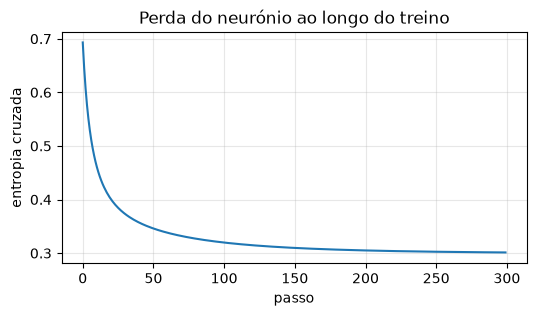

In [10]:
# Executar esta célula

w_n, b_n = np.zeros(2), 0.0
taxa = 0.5
perdas = []
for passo in range(300):
    p = neuronio(X_luas, w_n, b_n)
    perdas.append(entropia_cruzada(y_luas, p))
    erro = p - y_luas
    w_n -= taxa * X_luas.T @ erro / len(X_luas)          # dL/dw
    b_n -= taxa * erro.mean()                             # dL/db

exatidao = ((neuronio(X_luas, w_n, b_n) >= 0.5) == y_luas).mean()
print(f"Perda: {perdas[0]:.3f} → {perdas[-1]:.3f} | exatidão {exatidao:.1%}")
print("Pesos aprendidos:", w_n, "| scikit-learn:", logistica.coef_[0])

plt.figure(figsize=(6, 3))
plt.plot(perdas)
plt.title("Perda do neurónio ao longo do treino")
plt.xlabel("passo")
plt.ylabel("entropia cruzada")
plt.show()

O neurónio aprendeu sozinho pesos parecidos com os do scikit-learn (que usa um método mais sofisticado e alguma regularização). Mas a exatidão fica pelos 85 %: os dados `make_moons` têm a forma de duas meias-luas encaixadas, e uma fronteira reta não as separa bem. Precisamos de uma camada escondida.


## 4. Uma rede com uma camada escondida

### 4.1 A arquitetura e as dimensões

A nossa rede tem:
- uma **camada de entrada** com 2 atributos ($x_1$, $x_2$);
- uma **camada escondida** com $h$ neurónios ReLU;
- uma **camada de saída** com 1 neurónio sigmoide (a probabilidade da classe 1).

Os cálculos, para $n$ exemplos de uma só vez, são quatro linhas. A tabela mostra a **forma** (*shape*) de cada matriz. Quase todos os erros ao programar redes neuronais são formas que não batem certo, por isso vale a pena tê-la à vista.

| Passo | Cálculo | Forma (n exemplos, 2 entradas, h escondidos) |
| --- | --- | --- |
| entrada | $X$ | (n, 2) |
| soma da camada escondida | $Z_1 = X W_1 + b_1$ | (n, 2) @ (2, h) + (h,) → (n, h) |
| ativação escondida | $A_1 = \text{ReLU}(Z_1)$ | (n, h) |
| soma da saída | $Z_2 = A_1 W_2 + b_2$ | (n, h) @ (h, 1) + (1,) → (n, 1) |
| saída | $\hat{y} = A_2 = \sigma(Z_2)$ | (n, 1) |

O número de parâmetros é $2h + h$ (camada escondida) $+ h + 1$ (saída). Com $h = 16$: 65 parâmetros.

### 4.2 A inicialização dos pesos

Os pesos começam **aleatórios e pequenos**, com uma semente para que os resultados se possam repetir. Não podem começar todos iguais (por exemplo, a zero): todos os neurónios escondidos calculariam o mesmo, receberiam a mesma correção e continuariam iguais para sempre (vamos confirmá-lo na secção 5). Para ReLU, usa-se habitualmente a **inicialização de He**: uma normal com desvio-padrão $\sqrt{2 / n_{\text{entradas}}}$.

### 4.3 A propagação para a frente

Juntamos tudo numa classe (capítulo 20). Os parâmetros ficam num dicionário, `params`, para os podermos percorrer facilmente quando os atualizarmos. O método `propagar` devolve a previsão e também os valores intermédios (`cache`), que a retropropagação vai precisar.


In [11]:
# Executar esta célula

class RedeNeuronal:
    """Rede com uma camada escondida e uma saída sigmoide (classificação binária)."""

    def __init__(self, n_entradas: int, n_escondidos: int, ativacao: str = "relu", semente: int = 0):
        rng = np.random.default_rng(semente)
        self.ativacao = ativacao
        self.params = {
            "W1": rng.normal(0, np.sqrt(2 / n_entradas), size=(n_entradas, n_escondidos)),
            "b1": np.zeros(n_escondidos),
            "W2": rng.normal(0, np.sqrt(1 / n_escondidos), size=(n_escondidos, 1)),
            "b2": np.zeros(1),
        }

    def propagar(self, X: np.ndarray) -> tuple[np.ndarray, dict]:
        g, _ = ATIVACOES[self.ativacao]
        p = self.params
        Z1 = X @ p["W1"] + p["b1"]
        A1 = g(Z1)
        Z2 = A1 @ p["W2"] + p["b2"]
        A2 = sigmoide(Z2)
        return A2, {"X": X, "Z1": Z1, "A1": A1, "A2": A2}

    def prever_proba(self, X: np.ndarray) -> np.ndarray:
        return self.propagar(X)[0].ravel()

    def prever(self, X: np.ndarray) -> np.ndarray:
        return (self.prever_proba(X) >= 0.5).astype(int)

    def n_parametros(self) -> int:
        return sum(v.size for v in self.params.values())


rede = RedeNeuronal(n_entradas=2, n_escondidos=16)
A2, cache = rede.propagar(X_luas)
for nome in ["X", "Z1", "A1", "A2"]:
    print(f"{nome:<3} forma {cache[nome].shape}")
print("Parâmetros:", rede.n_parametros())
print("Primeiras previsões (ainda sem treino):", rede.prever_proba(X_luas)[:5].round(3))

X   forma (200, 2)
Z1  forma (200, 16)
A1  forma (200, 16)
A2  forma (200, 1)
Parâmetros: 65
Primeiras previsões (ainda sem treino): [0.625 0.761 0.505 0.874 0.763]


As formas batem certo com a tabela, e a rede já faz previsões. Mas, com pesos aleatórios, essas previsões não valem nada. Para aprender, a rede precisa de saber **como mudar cada um dos 65 pesos** para reduzir a perda: precisa dos gradientes.


## 5. Retropropagação: calcular todos os gradientes

### 5.1 A regra da cadeia num exemplo pequeno

A perda depende dos pesos através de uma **cadeia** de cálculos: o peso muda a soma $z$, que muda a ativação $a$, que muda a perda $L$. A **regra da cadeia** diz que, para saber quanto $L$ muda com $w$, multiplicam-se as variações de cada elo:

$$\frac{\partial L}{\partial w} = \frac{\partial L}{\partial a} \cdot \frac{\partial a}{\partial z} \cdot \frac{\partial z}{\partial w}$$

Vejamos com números, num único neurónio com $z = w x + b$, $a = \sigma(z)$ e uma perda simples $L = (a - y)^2$:


In [12]:
# Executar esta célula

x, y, w, b = 2.0, 1.0, 0.5, -0.3

# para a frente
z = w * x + b
a = sigmoide(z)
L = (a - y) ** 2
print(f"z = {z:.3f}   a = {a:.4f}   L = {L:.5f}")

# para trás, elo a elo
dL_da = 2 * (a - y)              # derivada de (a − y)²
da_dz = a * (1 - a)              # derivada da sigmoide
dz_dw = x                        # derivada de w·x + b em ordem a w
dL_dw = dL_da * da_dz * dz_dw
print(f"dL/da = {dL_da:.4f}   da/dz = {da_dz:.4f}   dz/dw = {dz_dw:.1f}   →   dL/dw = {dL_dw:.5f}")

# confirmação numérica: mexer w um bocadinho e ver quanto L muda
eps = 1e-6
L_mais = (sigmoide((w + eps) * x + b) - y) ** 2
print(f"Diferença finita: {(L_mais - L) / eps:.5f}")

z = 0.700   a = 0.6682   L = 0.11010
dL/da = -0.6636   da/dz = 0.2217   dz/dw = 2.0   →   dL/dw = -0.29427
Diferença finita: -0.29427


A derivada calculada pela regra da cadeia coincide com a medida «à força» (mexendo $w$ um bocadinho). A **retropropagação** (*backpropagation*) é só isto, aplicado a uma rede inteira: percorrer os cálculos **de trás para a frente**, da perda até à entrada, multiplicando as derivadas de cada passo e reaproveitando as que já foram calculadas.

### 5.2 As fórmulas para a nossa rede

Para a rede da secção 4, com entropia cruzada e $n$ exemplos, os gradientes são (lê-se de cima para baixo, que é o sentido inverso da propagação):

| Passo | Gradiente | Forma |
| --- | --- | --- |
| saída | $dZ_2 = \frac{1}{n}(A_2 - y)$ | (n, 1) |
| pesos da saída | $dW_2 = A_1^\top dZ_2$, $\; db_2 = \sum dZ_2$ | (h, 1), (1,) |
| volta à camada escondida | $dA_1 = dZ_2 W_2^\top$ | (n, h) |
| passa pela ativação | $dZ_1 = dA_1 \odot g'(Z_1)$ | (n, h) |
| pesos da camada escondida | $dW_1 = X^\top dZ_1$, $\; db_1 = \sum dZ_1$ | (2, h), (h,) |

Duas notas:
- o primeiro passo, $dZ_2 = A_2 - y$, é tão simples porque as derivadas da entropia cruzada e da sigmoide se **cancelam** parcialmente. É a mesma fórmula que usámos para o neurónio na secção 3.3;
- $\odot$ é a multiplicação **elemento a elemento** (o `*` do NumPy), não o produto de matrizes (`@`).

Cada gradiente tem **a mesma forma do parâmetro** a que se refere: é uma boa verificação.

Acrescentamos também uma **penalização L2** opcional (regularização, secção 6.3): somar $\frac{\lambda}{2}\sum w^2$ à perda acrescenta $\lambda W$ ao gradiente de cada matriz de pesos, e empurra os pesos para valores pequenos.

Para não repetir a classe, criamos uma **subclasse** que herda tudo e acrescenta a perda e os gradientes (capítulo 20, herança):


In [13]:
# Executar esta célula

class RedeComTreino(RedeNeuronal):
    """Acrescenta à RedeNeuronal o cálculo da perda e dos gradientes."""

    def perda(self, X: np.ndarray, y: np.ndarray, l2: float = 0.0) -> float:
        penalizacao = 0.5 * l2 * (np.sum(self.params["W1"] ** 2) + np.sum(self.params["W2"] ** 2))
        return entropia_cruzada(y, self.prever_proba(X)) + penalizacao

    def gradientes(self, X: np.ndarray, y: np.ndarray, l2: float = 0.0) -> dict[str, np.ndarray]:
        _, dg = ATIVACOES[self.ativacao]
        A2, c = self.propagar(X)
        p = self.params
        n = len(X)

        dZ2 = (A2 - y.reshape(-1, 1)) / n           # (n, 1)
        dW2 = c["A1"].T @ dZ2 + l2 * p["W2"]        # (h, 1)
        db2 = dZ2.sum(axis=0)                       # (1,)
        dA1 = dZ2 @ p["W2"].T                       # (n, h)
        dZ1 = dA1 * dg(c["Z1"])                     # (n, h)  elemento a elemento
        dW1 = c["X"].T @ dZ1 + l2 * p["W1"]         # (2, h)
        db1 = dZ1.sum(axis=0)                       # (h,)
        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}


rede = RedeComTreino(2, 16)
grads = rede.gradientes(X_luas, y_luas)
for nome in rede.params:
    print(f"{nome}: parâmetro {rede.params[nome].shape} | gradiente {grads[nome].shape}")

W1: parâmetro (2, 16) | gradiente (2, 16)
b1: parâmetro (16,) | gradiente (16,)
W2: parâmetro (16, 1) | gradiente (16, 1)
b2: parâmetro (1,) | gradiente (1,)


### 5.3 Verificar os gradientes

A retropropagação é fácil de programar mal: um transposto esquecido ou um sinal trocado e a rede aprende mal, sem dar erro nenhum. Por isso, antes de treinar, **verificamos os gradientes** como na secção 5.1: mexemos cada parâmetro um bocadinho para cima e para baixo e medimos a variação da perda (**diferenças finitas centradas**):

$$\frac{\partial L}{\partial w} \approx \frac{L(w + \varepsilon) - L(w - \varepsilon)}{2\varepsilon}$$

Comparamos com a retropropagação através do **erro relativo**: abaixo de $10^{-6}$, está certo. Usamos a ativação tanh, que é suave em todo o lado; a ReLU tem um «bico» em 0 onde as diferenças finitas podem falhar sem que haja erro no código.

É, na prática, um **teste automático** (anexo A2): se alguém alterar o código dos gradientes e o estragar, o `assert` falha.


In [14]:
# Executar esta célula

def gradiente_numerico(rede: RedeComTreino, X: np.ndarray, y: np.ndarray, l2: float = 0.0,
                       eps: float = 1e-5) -> dict[str, np.ndarray]:
    numericos = {}
    for nome, valor in rede.params.items():
        g = np.zeros_like(valor)
        for i in np.ndindex(valor.shape):          # percorre cada peso
            original = valor[i]
            valor[i] = original + eps
            mais = rede.perda(X, y, l2)
            valor[i] = original - eps
            menos = rede.perda(X, y, l2)
            valor[i] = original
            g[i] = (mais - menos) / (2 * eps)
        numericos[nome] = g
    return numericos


def erro_relativo(a: np.ndarray, b: np.ndarray) -> float:
    return float(np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b) + 1e-12))


rede_teste = RedeComTreino(2, 5, ativacao="tanh", semente=1)
analiticos = rede_teste.gradientes(X_luas[:20], y_luas[:20], l2=0.01)
numericos = gradiente_numerico(rede_teste, X_luas[:20], y_luas[:20], l2=0.01)
for nome in analiticos:
    erro = erro_relativo(analiticos[nome], numericos[nome])
    print(f"{nome}: erro relativo {erro:.2e}")
    assert erro < 1e-6, f"Gradiente de {nome} errado!"
print("Gradientes verificados.")

W1: erro relativo 9.38e-11
b1: erro relativo 2.16e-10
W2: erro relativo 2.16e-11
b2: erro relativo 1.49e-10
Gradientes verificados.


### 5.4 Porque não se começa com os pesos todos a zero

Agora que temos os gradientes, podemos confirmar o que foi dito na secção 4.2. Se todos os pesos começarem iguais, os neurónios escondidos recebem gradientes iguais e **nunca se diferenciam**: a camada escondida comporta-se como um só neurónio.


In [15]:
# Executar esta célula

simetrica = RedeComTreino(2, 4, ativacao="tanh")
for nome in simetrica.params:
    simetrica.params[nome][:] = 0.1                 # todos os pesos iguais
for _ in range(200):
    g = simetrica.gradientes(X_luas, y_luas)
    for nome in simetrica.params:
        simetrica.params[nome] -= 0.5 * g[nome]
print("W1 depois de 200 passos (cada coluna é um neurónio):\n", simetrica.params["W1"])

W1 depois de 200 passos (cada coluna é um neurónio):
 [[ 0.2301  0.2301  0.2301  0.2301]
 [-0.9575 -0.9575 -0.9575 -0.9575]]


As quatro colunas continuam iguais: os quatro neurónios são cópias uns dos outros. A inicialização aleatória **quebra a simetria**.


## 6. Treinar a rede

### 6.1 Dados, mini-lotes e o ciclo de treino

Usamos 600 pontos de `make_moons`, separados em **treino** (60 %), **validação** (20 %) e **teste** (20 %), como no módulo N2_04. A validação serve para acompanhar o treino e escolher opções; o teste fica guardado para o fim.

Em vez de usar todos os exemplos em cada passo, o treino usa **mini-lotes** (*mini-batches*): pequenos grupos de exemplos baralhados. Cada passo é mais rápido, e o ruído de usar só uma parte dos dados até ajuda a escapar a mínimos maus. Uma **época** é uma passagem completa por todos os dados de treino. Os mini-lotes são entregues por um **gerador** (capítulo 25), tal como o `DataLoader` do PyTorch fará no módulo seguinte.


In [16]:
# Executar esta célula

X, y = make_moons(n_samples=600, noise=0.25, random_state=42)
X_treino, X_resto, y_treino, y_resto = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_teste, y_val, y_teste = train_test_split(X_resto, y_resto, test_size=0.5, stratify=y_resto, random_state=42)
print(f"Treino {X_treino.shape} | validação {X_val.shape} | teste {X_teste.shape}")


def mini_lotes(X: np.ndarray, y: np.ndarray, tamanho: int, rng: np.random.Generator):
    """Gerador: baralha os exemplos e entrega-os em lotes de `tamanho`."""
    ordem = rng.permutation(len(X))
    for inicio in range(0, len(X), tamanho):
        idx = ordem[inicio:inicio + tamanho]
        yield X[idx], y[idx]


lotes = list(mini_lotes(X_treino, y_treino, 32, np.random.default_rng(0)))
print(f"{len(lotes)} lotes por época; formas do 1.º lote: {lotes[0][0].shape}, {lotes[0][1].shape}")

Treino (360, 2) | validação (120, 2) | teste (120, 2)
12 lotes por época; formas do 1.º lote: (32, 2), (32,)


O ciclo de treino repete, para cada época e cada lote: **propagar → calcular gradientes → atualizar os pesos**. No fim de cada época, registamos a perda e a exatidão no treino e na validação. A função também pode guardar «fotografias» da rede em algumas épocas e aplicar a **paragem antecipada** (secção 6.3).


In [17]:
# Executar esta célula

def exatidao(rede: RedeNeuronal, X: np.ndarray, y: np.ndarray) -> float:
    return float((rede.prever(X) == y).mean())


def treinar(rede: RedeComTreino, X_tr, y_tr, X_v, y_v, epocas: int = 300, taxa: float = 0.1,
            tamanho_lote: int = 32, l2: float = 0.0, paciencia: int | None = None,
            fotografias: tuple[int, ...] = (), semente: int = 0) -> tuple[dict, dict]:
    rng = np.random.default_rng(semente)
    historico = {"perda_treino": [], "perda_val": [], "exat_treino": [], "exat_val": []}
    fotos = {0: copy.deepcopy(rede.params)} if 0 in fotografias else {}
    melhor_perda, melhor_params, melhor_epoca = np.inf, None, 0

    for epoca in range(1, epocas + 1):
        for X_lote, y_lote in mini_lotes(X_tr, y_tr, tamanho_lote, rng):
            grads = rede.gradientes(X_lote, y_lote, l2)
            for nome in rede.params:
                rede.params[nome] -= taxa * grads[nome]          # descida do gradiente

        historico["perda_treino"].append(rede.perda(X_tr, y_tr))
        historico["perda_val"].append(rede.perda(X_v, y_v))
        historico["exat_treino"].append(exatidao(rede, X_tr, y_tr))
        historico["exat_val"].append(exatidao(rede, X_v, y_v))
        if epoca in fotografias:
            fotos[epoca] = copy.deepcopy(rede.params)

        if paciencia is not None:                                # paragem antecipada
            if historico["perda_val"][-1] < melhor_perda:
                melhor_perda, melhor_params, melhor_epoca = historico["perda_val"][-1], copy.deepcopy(rede.params), epoca
            elif epoca - melhor_epoca >= paciencia:
                rede.params = melhor_params
                print(f"Paragem antecipada na época {epoca}; repostos os pesos da época {melhor_epoca}.")
                break
    return historico, fotos

### 6.2 Treinar e acompanhar

Treinamos uma rede com 16 neurónios escondidos durante 300 épocas, guardando fotografias em quatro momentos para ver a **fronteira de decisão** a formar-se.


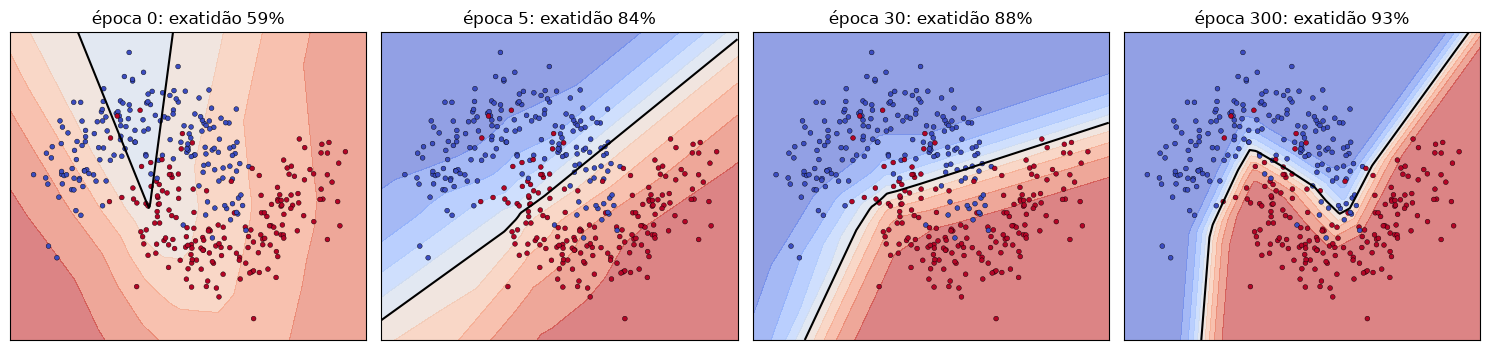

In [18]:
# Executar esta célula

def desenhar_fronteira(ax, rede: RedeNeuronal, X: np.ndarray, y: np.ndarray, titulo: str = "") -> None:
    x1, x2 = np.meshgrid(np.linspace(-1.8, 2.8, 250), np.linspace(-1.4, 1.9, 250))
    grelha = np.c_[x1.ravel(), x2.ravel()]
    prob = rede.prever_proba(grelha).reshape(x1.shape)
    ax.contourf(x1, x2, prob, levels=np.linspace(0, 1, 11), cmap="coolwarm", alpha=0.6)
    ax.contour(x1, x2, prob, levels=[0.5], colors="k", linewidths=1.5)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12, edgecolor="k", linewidths=0.3)
    ax.set(title=titulo, xticks=[], yticks=[])


rede = RedeComTreino(2, 16, semente=0)
historico, fotos = treinar(rede, X_treino, y_treino, X_val, y_val, epocas=300, taxa=0.1,
                           fotografias=(0, 5, 30, 300))

fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (epoca, params) in zip(axs, fotos.items()):
    instantaneo = RedeComTreino(2, 16)
    instantaneo.params = params
    desenhar_fronteira(ax, instantaneo, X_treino, y_treino,
                       f"época {epoca}: exatidão {exatidao(instantaneo, X_treino, y_treino):.0%}")
plt.tight_layout()
plt.show()

No início, a fronteira é uma linha quase arbitrária. Ao longo das épocas, dobra-se para acompanhar as duas meias-luas: é a camada escondida a construir uma fronteira **não linear**, que um só neurónio não conseguia.

As **curvas de aprendizagem** mostram a evolução da perda e da exatidão:


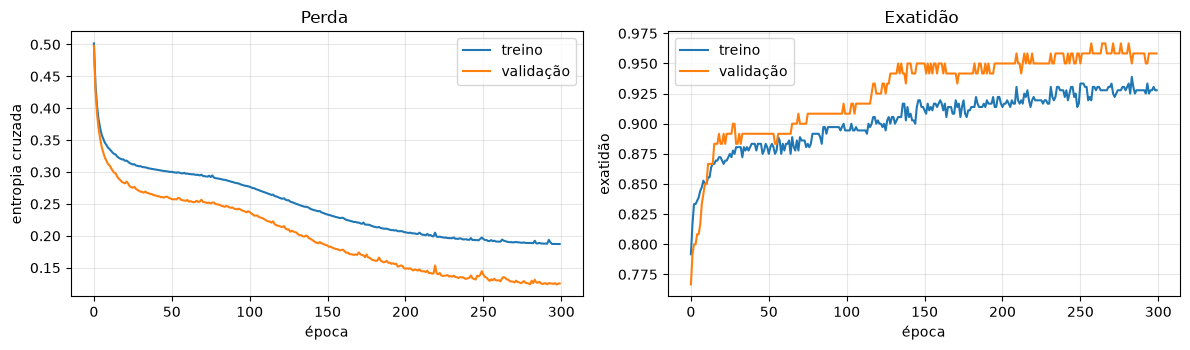

Exatidão final: treino 92.8% | validação 95.8%


In [19]:
# Executar esta célula

def curvas(historico: dict, titulo: str = "") -> None:
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
    axs[0].plot(historico["perda_treino"], label="treino")
    axs[0].plot(historico["perda_val"], label="validação")
    axs[0].set(title=f"Perda {titulo}", xlabel="época", ylabel="entropia cruzada")
    axs[1].plot(historico["exat_treino"], label="treino")
    axs[1].plot(historico["exat_val"], label="validação")
    axs[1].set(title=f"Exatidão {titulo}", xlabel="época", ylabel="exatidão")
    for ax in axs:
        ax.legend()
    plt.tight_layout()
    plt.show()


curvas(historico)
print(f"Exatidão final: treino {historico['exat_treino'][-1]:.1%} | validação {historico['exat_val'][-1]:.1%}")

As curvas de treino e de validação descem juntas e ficam próximas: a rede **generaliza** bem. Este é o comportamento que queremos ver. (A validação fica até um pouco melhor do que o treino: com só 120 exemplos, há alguma sorte na amostra; o que importa é que não se afasta.)

### 6.3 Sobreajuste, regularização L2 e paragem antecipada

Com 360 exemplos e 16 neurónios, a rede generalizou bem. Vejamos o que acontece com **poucos dados e com mais ruído** (50 exemplos de treino, gerados à parte) e uma rede **grande** (100 neurónios escondidos, 401 parâmetros: oito vezes mais parâmetros do que exemplos), treinada durante muito tempo:


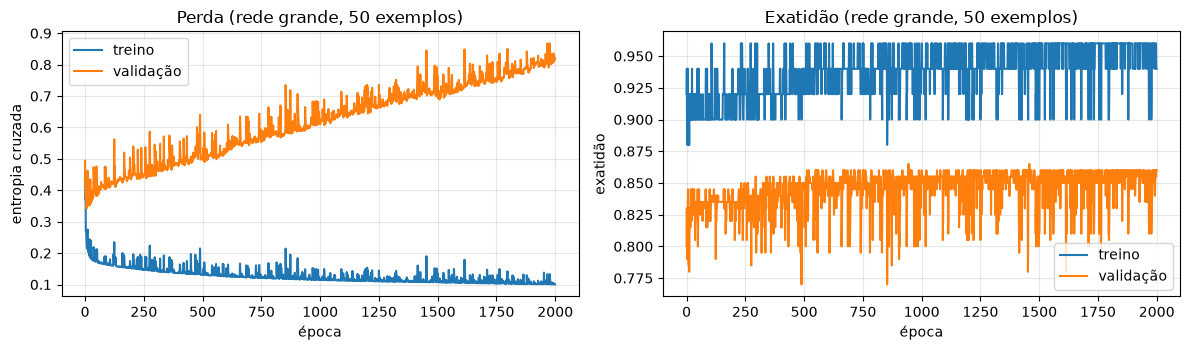

Perda de validação: mínima 0.342 na época 7; no fim 0.821
Exatidão: treino 94.0% | validação 86.0%


In [20]:
# Executar esta célula

X_pequeno, y_pequeno = make_moons(n_samples=400, noise=0.3, random_state=7)
X_pouco, y_pouco = X_pequeno[:50], y_pequeno[:50]              # 50 exemplos de treino
X_val2, y_val2 = X_pequeno[200:], y_pequeno[200:]              # 200 de validação

grande = RedeComTreino(2, 100, semente=0)
hist_grande, _ = treinar(grande, X_pouco, y_pouco, X_val2, y_val2, epocas=2000, taxa=0.05, tamanho_lote=16)
curvas(hist_grande, "(rede grande, 50 exemplos)")
perda_val = np.array(hist_grande["perda_val"])
print(f"Perda de validação: mínima {perda_val.min():.3f} na época {perda_val.argmin() + 1}; "
      f"no fim {perda_val[-1]:.3f}")
print(f"Exatidão: treino {hist_grande['exat_treino'][-1]:.1%} | validação {hist_grande['exat_val'][-1]:.1%}")

É o **sobreajuste** (*overfitting*): a perda de treino continua a descer, porque a rede vai «decorando» os 50 exemplos, ruído incluído, mas a perda de **validação** atinge o mínimo em poucas épocas e depois **sobe** para mais do dobro.

Repara num pormenor importante: a **exatidão** de validação quase não mudou. O sobreajuste nota-se primeiro na **perda**, porque a rede fica cada vez mais **confiante**, também nos exemplos que classifica mal: as probabilidades encostam a 0 e a 1, e a entropia cruzada castiga muito os erros confiantes (secção 3.1). Um modelo assim é perigoso quando as probabilidades são usadas para decidir, como no *lift* do N3_03. Por isso se acompanha a **perda de validação**, e não só a exatidão.

Dois remédios clássicos:
- **regularização L2** (`l2`): penaliza pesos grandes, o que obriga a fronteiras mais suaves e a probabilidades menos extremas;
- **paragem antecipada** (`paciencia`): pára quando a perda de validação não melhora durante um certo número de épocas, e repõe os melhores pesos.


Paragem antecipada na época 107; repostos os pesos da época 7.


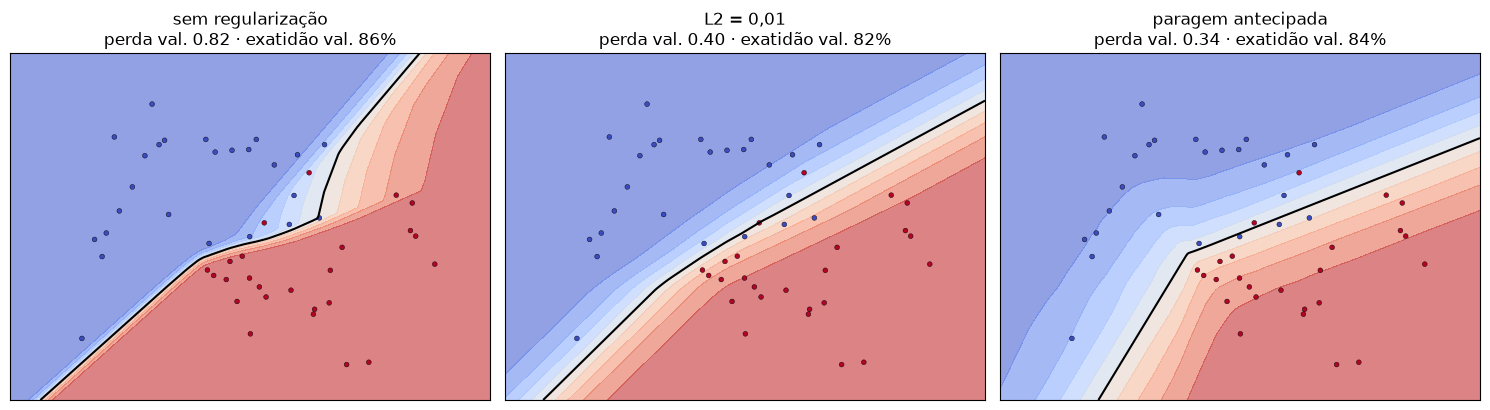

In [21]:
# Executar esta célula

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
config = [("sem regularização", {}), ("L2 = 0,01", {"l2": 0.01}), ("paragem antecipada", {"paciencia": 100})]
for ax, (nome, opcoes) in zip(axs, config):
    r = RedeComTreino(2, 100, semente=0)
    treinar(r, X_pouco, y_pouco, X_val2, y_val2, epocas=2000, taxa=0.05, tamanho_lote=16, **opcoes)
    desenhar_fronteira(ax, r, X_pouco, y_pouco,
                       f"{nome}\nperda val. {r.perda(X_val2, y_val2):.2f} · exatidão val. {exatidao(r, X_val2, y_val2):.0%}")
plt.tight_layout()
plt.show()

Sem regularização, a fronteira contorce-se para apanhar pontos isolados do treino, e as zonas de cor forte (probabilidades extremas) avançam até junto da fronteira. Com L2 ou com paragem antecipada, a fronteira fica mais suave, as probabilidades mais moderadas e a **perda de validação cai para cerca de metade**, com uma exatidão semelhante. Na prática, usam-se os dois em conjunto. E a melhor defesa contra o sobreajuste continua a ser **ter mais dados**.

**Experimenta:** na rede grande, troca `l2=0.01` por `0.001` e por `0.1`. O que acontece à fronteira quando a regularização é forte demais?


In [22]:
# Executar esta célula

# Utiliza esta célula para as tuas experiências

## 7. Comparar com o scikit-learn e ligar ao PyTorch

### 7.1 A nossa rede, o scikit-learn e uma referência linear

Avaliamos agora, **uma única vez**, no conjunto de teste. Comparamos três modelos:
- a nossa rede (16 neurónios ReLU, treinada na secção 6.2);
- o `MLPClassifier` do scikit-learn com a **mesma arquitetura** (é também uma rede neuronal, com o otimizador Adam). Com a taxa de aprendizagem por omissão (0,001), neste problema pára de treinar cedo demais e fica pelos 85 %: usamos 0,01 (mais um exemplo da importância da taxa de aprendizagem);
- a regressão logística, como **referência linear** (um só neurónio).


regressão logística (1 neurónio)   exatidão no teste: 83.3%
a nossa rede (NumPy)               exatidão no teste: 92.5%
MLPClassifier (scikit-learn)       exatidão no teste: 94.2%


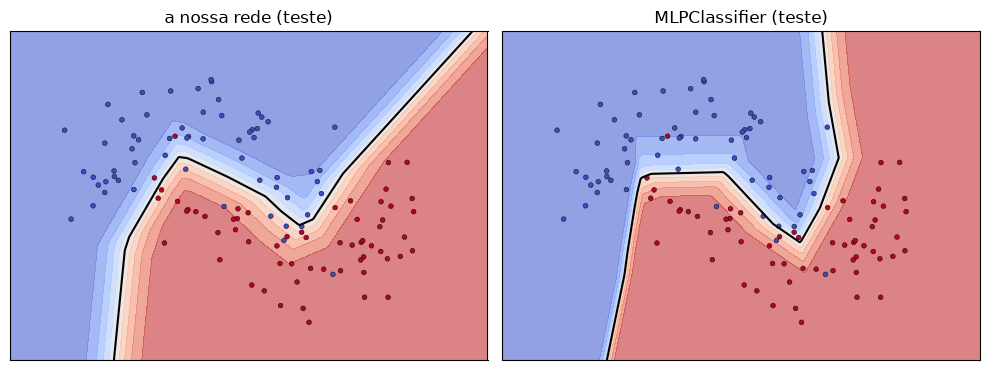

In [23]:
# Executar esta célula

mlp = MLPClassifier(hidden_layer_sizes=(16,), activation="relu", learning_rate_init=0.01,
                    max_iter=2000, random_state=0).fit(X_treino, y_treino)
linear = LogisticRegression().fit(X_treino, y_treino)

resultados = {
    "regressão logística (1 neurónio)": linear.score(X_teste, y_teste),
    "a nossa rede (NumPy)": exatidao(rede, X_teste, y_teste),
    "MLPClassifier (scikit-learn)": mlp.score(X_teste, y_teste),
}
for nome, valor in resultados.items():
    print(f"{nome:<34} exatidão no teste: {valor:.1%}")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
desenhar_fronteira(axs[0], rede, X_teste, y_teste, "a nossa rede (teste)")


class Adaptador:                                   # deixa desenhar modelos do scikit-learn com a mesma função
    def __init__(self, modelo): self.modelo = modelo
    def prever_proba(self, X): return self.modelo.predict_proba(X)[:, 1]


desenhar_fronteira(axs[1], Adaptador(mlp), X_teste, y_teste, "MLPClassifier (teste)")
plt.tight_layout()
plt.show()

A nossa rede, escrita de raiz em poucas dezenas de linhas, fica ao nível do `MLPClassifier` (as pequenas diferenças vêm do otimizador e da inicialização), e as duas ficam muito acima da referência linear: a camada escondida é o que faz a diferença.

### 7.2 O que o PyTorch automatiza

Tudo o que escrevemos à mão tem um equivalente no PyTorch, que vais usar no módulo seguinte:

| Neste módulo (à mão) | No PyTorch |
| --- | --- |
| `params` com `W1`, `b1`, … e a inicialização de He | `nn.Linear(2, 16)` cria e inicializa os pesos |
| `relu`, `sigmoide` | `nn.ReLU()`, `nn.Sigmoid()` |
| `RedeNeuronal.propagar` | `forward` de uma classe que herda de `nn.Module` |
| `entropia_cruzada` | `nn.BCELoss()` (ou `nn.BCEWithLogitsLoss()`) |
| `RedeComTreino.gradientes` (a retropropagação) | `perda.backward()`: o **autograd** calcula todos os gradientes sozinho |
| `params[nome] -= taxa * grads[nome]` | `otimizador.step()` com `torch.optim.SGD` ou `Adam` |
| `mini_lotes` (o gerador) | `DataLoader(dados, batch_size=32, shuffle=True)` |
| a penalização `l2` | `weight_decay=` no otimizador |
| `gradiente_numerico` | `torch.autograd.gradcheck` |

Para teres uma ideia, a mesma rede e o mesmo ciclo de treino em PyTorch (não é preciso correr):

```python
modelo = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1), nn.Sigmoid())
otimizador = torch.optim.SGD(modelo.parameters(), lr=0.1)
perda_fn = nn.BCELoss()

for epoca in range(300):
    for X_lote, y_lote in carregador:                 # DataLoader
        perda = perda_fn(modelo(X_lote), y_lote)
        otimizador.zero_grad()
        perda.backward()                              # retropropagação automática
        otimizador.step()                             # descida do gradiente
```

Cada linha corresponde a uma parte deste módulo. A diferença é que o PyTorch faz a retropropagação para **qualquer** rede, com qualquer número de camadas, e corre em GPU.


## 8. Experimenta

### Exercício 1 – Outra função de ativação

Treina uma `RedeComTreino` com 16 neurónios e ativação **tanh**, com as mesmas opções da secção 6.2, e compara as curvas e a exatidão na validação com as da ReLU.


In [24]:
# Executar esta célula

# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
rede_tanh = RedeComTreino(2, 16, ativacao="tanh", semente=0)
hist_tanh, _ = treinar(rede_tanh, X_treino, y_treino, X_val, y_val, epocas=300, taxa=0.1)
curvas(hist_tanh, "(tanh)")
print(f"Validação: tanh {hist_tanh['exat_val'][-1]:.1%} | ReLU {historico['exat_val'][-1]:.1%}")
# Neste problema pequeno, as duas chegam a resultados parecidos. A tanh costuma
# descer um pouco mais devagar no início; em redes profundas, a ReLU tem a vantagem
# de não «encolher» o gradiente (secção 2).
```

</details>


### Exercício 2 – Quantos neurónios escondidos?

Treina redes com 1, 2, 4, 16 e 64 neurónios escondidos (300 épocas, taxa 0,1) e desenha a fronteira de decisão de cada uma, com a exatidão na validação no título. A partir de quantos neurónios a rede consegue separar as meias-luas?


In [25]:
# Executar esta célula

# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
tamanhos = [1, 2, 4, 16, 64]
fig, axs = plt.subplots(1, len(tamanhos), figsize=(17, 3.4))
for ax, h in zip(axs, tamanhos):
    r = RedeComTreino(2, h, semente=0)
    treinar(r, X_treino, y_treino, X_val, y_val, epocas=300, taxa=0.1)
    desenhar_fronteira(ax, r, X_treino, y_treino, f"{h} neurónio(s): validação {exatidao(r, X_val, y_val):.0%}")
plt.tight_layout()
plt.show()
# Com 1 ou 2 neurónios, a fronteira é quase uma reta (como a regressão logística).
# Com 4, começa a dobrar-se; com 16 ou mais, acompanha as meias-luas. Mais neurónios
# dão fronteiras mais flexíveis, que com poucos dados podem levar ao sobreajuste (secção 6.3).
```

</details>


### Exercício 3 – Descida do gradiente com *momentum*

O ***momentum*** junta à descida do gradiente uma «velocidade»: cada passo continua um pouco no sentido dos passos anteriores, o que acelera nas zonas planas e amortece as oscilações. Para cada parâmetro:

$$v \leftarrow \beta v - \eta \nabla L \qquad w \leftarrow w + v$$

com $\beta = 0{,}9$ habitualmente. Escreve uma função `treinar_momentum` (podes simplificar: sem fotografias nem paragem antecipada) e compara a perda de treino ao longo de 100 épocas, com e sem *momentum*, com a mesma taxa de aprendizagem baixa (0,02).


In [26]:
# Executar esta célula

# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def treinar_momentum(rede, X_tr, y_tr, epocas=100, taxa=0.02, beta=0.9, tamanho_lote=32, semente=0):
    rng = np.random.default_rng(semente)
    velocidade = {nome: np.zeros_like(valor) for nome, valor in rede.params.items()}
    perdas = []
    for _ in range(epocas):
        for X_lote, y_lote in mini_lotes(X_tr, y_tr, tamanho_lote, rng):
            grads = rede.gradientes(X_lote, y_lote)
            for nome in rede.params:
                velocidade[nome] = beta * velocidade[nome] - taxa * grads[nome]
                rede.params[nome] += velocidade[nome]
        perdas.append(rede.perda(X_tr, y_tr))
    return perdas


sem = treinar_momentum(RedeComTreino(2, 16, semente=0), X_treino, y_treino, beta=0.0)   # beta = 0: sem momentum
com = treinar_momentum(RedeComTreino(2, 16, semente=0), X_treino, y_treino, beta=0.9)
plt.plot(sem, label="sem momentum")
plt.plot(com, label="com momentum (β = 0,9)")
plt.xlabel("época")
plt.ylabel("perda de treino")
plt.legend()
plt.show()
print(f"Perda final: sem {sem[-1]:.3f} | com {com[-1]:.3f}")
```

</details>


## Verifica o que aprendeste

1. Que duas operações faz um neurónio? Qual é a relação entre um neurónio sigmoide e a regressão logística?
2. Porque é que um só neurónio não resolve o XOR, e porque é que empilhar camadas **sem** função de ativação também não resolve?
3. O que acontece na descida do gradiente quando a taxa de aprendizagem é demasiado grande? E demasiado pequena?
4. Numa rede com 2 entradas, 16 neurónios escondidos e 1 saída, qual é a forma de `W1` e de `W2`, e quantos parâmetros tem a rede?
5. O que é a retropropagação, e porque é que se verifica com diferenças finitas?
6. Porque é que os pesos não podem começar todos a zero?
7. Como se reconhece o sobreajuste nas curvas de aprendizagem, e que duas técnicas o combatem?
8. Que linha do PyTorch substitui o método `gradientes` que escreveste?

<details>
<summary><b>Ver respostas</b></summary>

1. Uma soma ponderada das entradas mais o viés, $z = x \cdot w + b$, e uma função de ativação, $a = g(z)$. Um neurónio com sigmoide calcula exatamente o mesmo que uma regressão logística.
2. A fronteira de um neurónio é uma reta, e nenhuma reta separa os pontos do XOR. Sem ativação não linear, várias camadas equivalem a uma só multiplicação de matrizes, ou seja, continuam a dar uma fronteira reta.
3. Grande demais: os passos ultrapassam o mínimo e a perda aumenta (diverge). Pequena demais: aprende, mas muito devagar.
4. `W1` tem forma (2, 16) e `W2` (16, 1); com os viéses `b1` (16) e `b2` (1), são 32 + 16 + 16 + 1 = 65 parâmetros.
5. É o cálculo de todos os gradientes da perda, aplicando a regra da cadeia de trás para a frente. Verifica-se com diferenças finitas porque é fácil programá-la mal sem que apareça nenhum erro: a rede só aprende pior.
6. Porque todos os neurónios escondidos calculariam o mesmo e receberiam as mesmas correções: nunca se diferenciariam (simetria). A inicialização aleatória quebra essa simetria.
7. A perda de treino continua a descer enquanto a de validação atinge um mínimo e volta a subir (a exatidão pode quase não mudar: a rede fica confiante demais nos erros). Combate-se com regularização (L2) e paragem antecipada (e, sempre que possível, com mais dados).
8. `perda.backward()`: o *autograd* do PyTorch calcula todos os gradientes automaticamente.

</details>

## Leitura recomendada

- Nielsen, M. (2015). *[Neural Networks and Deep Learning](http://neuralnetworksanddeeplearning.com/)*. Determination Press. Livro gratuito em linha; os capítulos 1 e 2 seguem o mesmo caminho deste módulo, até à retropropagação.
- Goodfellow, I., Bengio, Y. e Courville, A. (2016). *[Deep Learning](https://www.deeplearningbook.org/)*. Cambridge, MA: MIT Press. Capítulo 6 (redes *feedforward*) e secção 8.3 (*momentum*).
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). Sebastopol: O'Reilly Media. Capítulo 10.
- Grus, J. (2019). *Data Science from Scratch* (2.ª ed.). Sebastopol: O'Reilly Media. Capítulos 18 e 19: redes neuronais e *deep learning* de raiz, em Python.
- 3Blue1Brown. *[Neural networks](https://www.3blue1brown.com/topics/neural-networks)*. Série de vídeos com animações sobre redes, descida do gradiente e retropropagação.
- [Documentação do `MLPClassifier`](https://scikit-learn.org/stable/modules/neural_networks_supervised.html) do scikit-learn.
- **Módulos relacionados:** N2_04 (regressão logística e métricas de classificação), N3_03 (o processo KDD) e N3_05 (PyTorch, a seguir).
